# 07 · Precision axioms: LMP against PM4Py

Tax et al. (2018) proposed five axioms that a language-level precision measure should satisfy. LMP satisfies all of them for any fixed full-support prior, because each axiom reduces to one of two facts about

$$\mathrm{LMP}_\mu(L, M) = \frac{\mu(\tilde L \cap \mathcal L(M))}{\mu(\mathcal L(M))}$$

the numerator only grows when the log grows, and the denominator only grows when the model language grows. [Tutorial 02](02_controlled_examples.ipynb) shows LMP on each axiom's toy example. This notebook goes the other way: it builds a witness for each axiom on which **PM4Py's token-based, alignment-based and footprint precision** are put to the same test, then collects the verdicts in one scorecard and checks the proof on random instances.

A ✗ means *the notebook contains a counterexample to that axiom*, not that the metric is wrong. Replay-based measures answer a different question; the axioms specify language precision.

In [1]:
import os, warnings
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
warnings.filterwarnings("ignore", category=DeprecationWarning)

import itertools, random
import language_mass_precision as lmp
import pm4py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pm4py.objects.petri_net.obj import PetriNet, Marking
from pm4py.objects.petri_net.utils import petri_utils
from language_mass_precision.objects.automaton import accepts
pd.set_option("display.precision", 6)
print("PM4Py", pm4py.__version__)

PM4Py 2.7.23.12


The prior is part of the metric, so it is declared once, before anything is compared: a geometric length prior with $\lambda=0.7$ and a power-law prior with $\alpha=2$, both with a uniform activity prior (the values used by the library's own axiom tests in `tests/test_axioms.py`). Every model compared below is scored under the same prior and the same alphabet.

In [2]:
GEO = dict(length_prior="geometric", length_parameter=0.7)
POW = dict(length_prior="power_law", length_parameter=2.0)

METRICS = ["LMP geo", "LMP pow", "PM4Py token", "PM4Py align", "PM4Py footprint"]
PM4PY = {"PM4Py token": pm4py.precision_token_based_replay,
         "PM4Py align": pm4py.precision_alignments,
         "PM4Py footprint": pm4py.conformance.precision_footprints}
RESULTS, WITNESS = {}, {}          # filled by verdict(), read by the scorecard


def tree(text):
    """A model *builder*: each call returns a freshly built (net, im, fm). Builders let us re-run PM4Py on identical new copies."""
    return lambda: pm4py.convert_to_petri_net(pm4py.parse_process_tree(text))


def toy(name, model):
    return lambda: lmp.datasets.load_toy(name).models[model]


def lmp_values(log, models, alphabet=None):
    out = {}
    for name, prior in (("LMP geo", GEO), ("LMP pow", POW)):
        t = lmp.rank_models(log, models, alphabet=alphabet, **prior).set_index("model")
        out[name] = ((t["lower"] + t["upper"]) / 2).to_dict()        # exact values have lower == upper
    return out


def scores(log, builders, alphabet=None, runs=15):
    """One row per model. A PM4Py metric is evaluated on `runs` freshly built copies of the model;
    if the copies disagree, the cell holds the pair (lowest, highest)."""
    lmp_part = lmp_values(log, {name: build() for name, build in builders.items()}, alphabet)
    rows = {}
    for name, build in builders.items():
        row = {m: lmp_part[m][name] for m in ("LMP geo", "LMP pow")}
        for metric, fn in PM4PY.items():
            vals = [fn(log, *build()) for _ in range(runs)]
            row[metric] = min(vals) if max(vals) - min(vals) < 1e-9 else (min(vals), max(vals))
        rows[name] = row
    return pd.DataFrame(rows).T


def lohi(x):
    return x if isinstance(x, tuple) else (x, x)


def fmt(x):
    lo, hi = lohi(x)
    return f"{lo:.4f}" if lo == hi else f"{lo:.4f} | {hi:.4f}"


def verdict(axiom, relation, first, second, witness, tol=1e-6):
    """Apply an axiom's inequality to two score rows ('>=', '>' or '=='). A metric that returns several values
    for identical models must satisfy the axiom for every one of them."""
    out = {}
    for m in METRICS:
        (flo, fhi), (slo, shi) = lohi(first[m]), lohi(second[m])
        ok = {">=": flo - shi >= -tol, ">": flo - shi > tol, "==": max(fhi, shi) - min(flo, slo) <= tol}[relation]
        RESULTS.setdefault(axiom, {}).setdefault(m, True)
        if not ok:
            RESULTS[axiom][m] = False
            WITNESS.setdefault((axiom, m), witness)
        out[m] = "✓" if ok else "✗"
    return pd.Series(out)


def show(frame, verdicts):
    table = frame.astype(object).apply(lambda col: col.map(fmt))
    table.loc["axiom holds?"] = verdicts
    return table

## A1 · Determinism

*The same log and model must always give the same value, with no outcome that depends on an arbitrary choice such as which replay path is followed.*

LMP is a fixed function of two sets and the declared prior, so there is nothing to choose. The test uses models whose labels are duplicated (two transitions carry the same activity), where a replay can fire either copy. Each model is rebuilt 30 times, identical content in new objects, and every metric is evaluated on every copy.

In [3]:
log_dup = lmp.traces_to_dataframe({("a", "b", "c"): 3, ("a", "d", "c"): 3})
decoy = lmp.datasets.load_toy("decoy_stress")
subjects = {
    "three copies of a-?-c": (log_dup, tree("X(->('a','b','c'), ->('a','d','c'), ->('a','e','c'))")),
    "decoy toy, larger":     (decoy.log, toy("decoy_stress", "larger")),
}

rows = {}
for name, (log, build) in subjects.items():
    values = {m: [] for m in METRICS}
    for _ in range(30):
        model = build()
        for m, v in lmp_values(log, {"M": model}).items():
            values[m].append(v["M"])
        for m, fn in PM4PY.items():
            values[m].append(fn(log, *model))
    for m in METRICS:
        ok = max(values[m]) - min(values[m]) <= 1e-12
        RESULTS.setdefault("A1 determinism", {}).setdefault(m, True)
        if not ok:
            RESULTS["A1 determinism"][m] = False
            WITNESS.setdefault(("A1 determinism", m), name)
    rows[name] = {m: " | ".join(f"{v:.4f}" for v in sorted({round(x, 4) for x in values[m]})) for m in METRICS}
pd.DataFrame(rows).T

,LMP geo,LMP pow,PM4Py token,PM4Py align,PM4Py footprint
three copies of a-?-c,0.6667,0.6667,0.5000 | 1.0000,0.8000,0.6667
"decoy toy, larger",0.8696,0.8705,0.6667 | 1.0000,0.7143,0.5000


LMP, alignment and footprint precision return one value for every copy. **Token-based replay does not**: replaying through a duplicated label requires choosing a transition, and which one PM4Py picks depends on its iteration order (here, on object memory layout; the same model can give another number in another Python process). That is the situation A1 excludes. Wherever a PM4Py metric is unstable, the tables below show `low | high`, and an axiom counts as satisfied only if it holds for every value the metric can return.

## A2 · Monotonicity under model-language inclusion

*If $\tilde L \subseteq \mathcal L(M_1) \subseteq \mathcal L(M_2)$, then $\mathrm{prec}(L, M_1) \ge \mathrm{prec}(L, M_2)$.*

The log fits both models, so the numerator is the same; a larger language can only enlarge the denominator. The witness is the decoy toy: $M_1$ has exactly the log language but is cluttered with dead visible branches, $M_2$ is clean but strictly larger.

In [4]:
builders = {"M1 (log language + dead branches)": toy("decoy_stress", "with_decoys"),
            "M2 (clean, larger language)": toy("decoy_stress", "larger")}
frame = scores(decoy.log, builders)
first, second = frame.iloc[0], frame.iloc[1]
show(frame, verdict("A2 language inclusion", ">=", first, second, "decoy toy"))

,LMP geo,LMP pow,PM4Py token,PM4Py align,PM4Py footprint
M1 (log language + dead branches),1.0000,1.0000,0.3125,0.3125,0.3125
"M2 (clean, larger language)",0.8696,0.8705,0.6667 | 1.0000,0.7143,0.5000
axiom holds?,✓,✓,✗,✗,✗


LMP gives $M_1$ a perfect 1. All three PM4Py metrics prefer the larger model: dead branches are enabled during replay, so replay-based measures count them as imprecision although they add nothing to the language.

The proof works for any full-support prior, so the ordering must survive any prior. Check it on 200 random ones (random $\lambda$ or $\alpha$, random activity distribution):

In [5]:
rng = np.random.default_rng(42)
models = {"M1": builders["M1 (log language + dead branches)"](), "M2": builders["M2 (clean, larger language)"]()}
sigma = sorted(set(decoy.log["concept:name"]).union(*(lmp.compile_model(*m).labels for m in models.values())))

gaps = []
for _ in range(200):
    kind = rng.choice(["geometric", "power_law"])
    par = rng.uniform(0.05, 0.95) if kind == "geometric" else rng.uniform(1.1, 4.0)
    pi = dict(zip(sigma, rng.dirichlet(np.ones(len(sigma)))))
    t = lmp.rank_models(decoy.log, models, length_prior=kind, length_parameter=par, activity_prior=pi).set_index("model")
    gaps.append(t.loc["M1", "lower"] - t.loc["M2", "upper"])
print(f"smallest LMP(M1) - LMP(M2) over 200 random priors: {min(gaps):.4f}")
assert min(gaps) >= 0

smallest LMP(M1) - LMP(M2) over 200 random priors: 0.0023


## A3 · The flower model as maximal generality

*A non-empty fitting log must score strictly higher on any proper model language than on the flower model $\Sigma^*$.*

The flower's denominator is the whole trace space, $\mu(\Sigma^*) = 1$, and every proper language has strictly smaller mass because $\mu$ has full support. (The flower toy is in [tutorial 02](02_controlled_examples.ipynb).)

To stress it, take the model $a \to b \to c$ (language $\{abc\}$, log $= 5 \times abc$) and add $k$ decoy transitions that are enabled at the start but lead into a dead end. The language is unchanged for every $k$ and remains a proper subset of $\Sigma^*$, so the model must keep beating the flower over $\{a, b, c\}$ however many decoys we add.

In [6]:
def decoy_net(k):
    """a -> b -> c plus k enabled-but-dead visible transitions at the start. L(M) = {abc} for every k."""
    net = PetriNet(f"decoys_{k}")
    p = [PetriNet.Place(f"p{i}") for i in range(4)]
    for place in p:
        net.places.add(place)
    for label, src, dst in [("a", 0, 1), ("b", 1, 2), ("c", 2, 3)]:
        t = PetriNet.Transition(f"t_{label}", label); net.transitions.add(t)
        petri_utils.add_arc_from_to(p[src], t, net); petri_utils.add_arc_from_to(t, p[dst], net)
    for i in range(k):
        dead = PetriNet.Place(f"dead{i}"); net.places.add(dead)
        t = PetriNet.Transition(f"x{i}", f"x{i}"); net.transitions.add(t)
        petri_utils.add_arc_from_to(p[0], t, net); petri_utils.add_arc_from_to(t, dead, net)
    return net, Marking({p[0]: 1}), Marking({p[3]: 1})


log = lmp.traces_to_dataframe({("a", "b", "c"): 5})
ks = [0, 2, 5, 10, 20, 50]
builders = {f"{k} decoys": (lambda k=k: decoy_net(k)) for k in ks}
builders["flower"] = tree("*(tau, X('a', 'b', 'c'))")
frame = scores(log, builders, alphabet=["a", "b", "c"])

flags = pd.DataFrame([verdict("A3 flower model", ">", frame.loc[f"{k} decoys"], frame.loc["flower"], f"{k} decoy branches vs flower")
                      for k in ks])
show(frame, flags.eq("✓").all().map({True: "✓", False: "✗"}))

,LMP geo,LMP pow,PM4Py token,PM4Py align,PM4Py footprint
0 decoys,1.0000,1.0000,1.0000,1.0000,1.0000
2 decoys,1.0000,1.0000,0.6000,0.6000,1.0000
5 decoys,1.0000,1.0000,0.3750,0.3750,1.0000
10 decoys,1.0000,1.0000,0.2308,0.2308,1.0000
20 decoys,1.0000,1.0000,0.1304,0.1304,1.0000
50 decoys,1.0000,1.0000,0.0566,0.0566,1.0000
flower,0.0038,0.0014,0.3333,0.3333,0.2222
axiom holds?,✓,✓,✗,✗,✓


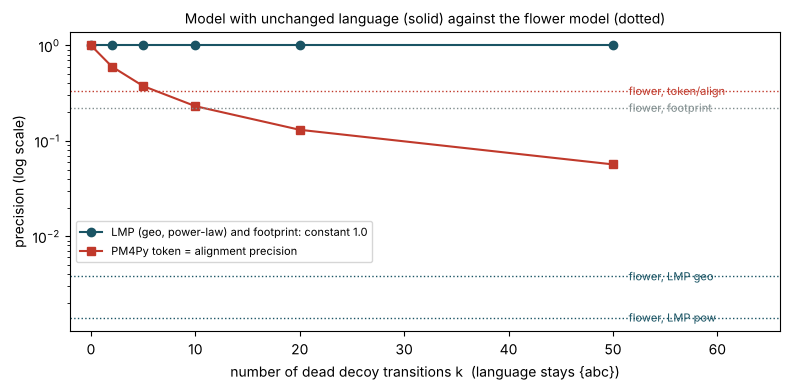

In [7]:
vals = {m: [lohi(frame.loc[f"{k} decoys", m])[0] for k in ks] for m in METRICS}
assert np.allclose(vals["PM4Py token"], vals["PM4Py align"])                                  # identical curves: draw once
assert all(np.allclose(vals[m], 1.0) for m in ["LMP geo", "LMP pow", "PM4Py footprint"])      # flat at 1: draw once
flower = {m: lohi(frame.loc["flower", m])[0] for m in METRICS}

fig, ax = plt.subplots(figsize=(8, 4))
teal, red, grey = "#1a5464", "#c0392b", "#7f8c8d"
ax.plot(ks, vals["LMP geo"], "o-", color=teal, label="LMP (geo, power-law) and footprint: constant 1.0")
ax.plot(ks, vals["PM4Py token"], "s-", color=red, label="PM4Py token = alignment precision")
for y, color, text in [(flower["PM4Py token"], red, "flower, token/align"), (flower["PM4Py footprint"], grey, "flower, footprint"),
                       (flower["LMP geo"], teal, "flower, LMP geo"), (flower["LMP pow"], teal, "flower, LMP pow")]:
    ax.axhline(y, color=color, ls=":", lw=1)
    ax.text(51.5, y, text, va="center", fontsize=8, color=color)
ax.set_xlim(-2, 66); ax.set_yscale("log")
ax.set_xlabel("number of dead decoy transitions k  (language stays {abc})"); ax.set_ylabel("precision (log scale)")
ax.set_title("Model with unchanged language (solid) against the flower model (dotted)", fontsize=10)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(0.0, 0.3)); fig.tight_layout()

LMP stays at 1 for every $k$, far above its flower values (about 0.004 geometric, 0.001 power-law), because decoys do not change $\mathcal L(M)$. Token-based and alignment precision (identical curves here) fall *below the flower's 0.333* between 5 and 10 decoys: a model that allows only $abc$ is declared less precise than a model that allows every trace. Footprint precision ignores the dead branches and passes.

## A4 · Invariance under model-language equivalence

*If $\mathcal L(M_1) = \mathcal L(M_2)$ then $\mathrm{prec}(L, M_1) = \mathrm{prec}(L, M_2)$.*

LMP is defined from $\tilde L$ and $\mathcal L(M)$ alone; the Petri net is only a way to obtain the language (the library compiles it to a DFA over visible labels), so silent transitions, duplicate labels and internal structure disappear in that step. The witness is two models of the same three-trace language: one choice after $a$, and three separate copies of the sequence. The silent-routing pair is in [tutorial 02](02_controlled_examples.ipynb).

In [8]:
choice = tree("->('a', X('b', 'd', 'e'), 'c')")
copies = tree("X(->('a','b','c'), ->('a','d','c'), ->('a','e','c'))")


def language_up_to(model, sigma, max_len=5):
    dfa = lmp.compile_model(*model).dfa
    return {w for n in range(max_len + 1) for w in itertools.product(sigma, repeat=n) if accepts(dfa, w)}


same = language_up_to(choice(), "abcde") == language_up_to(copies(), "abcde")
print("same language (all traces up to length 5):", same)
assert same

same language (all traces up to length 5): True


In [9]:
log = lmp.traces_to_dataframe({("a", "b", "c"): 3, ("a", "d", "c"): 3})
frame = scores(log, {"M1: choice after a": choice, "M2: three copies (duplicate labels)": copies})
show(frame, verdict("A4 language equivalence", "==", frame.iloc[0], frame.iloc[1], "duplicate-label vs choice model"))

,LMP geo,LMP pow,PM4Py token,PM4Py align,PM4Py footprint
M1: choice after a,0.6667,0.6667,0.8000,0.8000,0.6667
M2: three copies (duplicate labels),0.6667,0.6667,0.5000 | 1.0000,0.8000,0.6667
axiom holds?,✓,✓,✗,✓,✓


LMP returns the same value for both (the unseen trace $aec$ is one of three allowed traces under either structure). Token-based precision is 0.8 for the choice model but returns 0.5 *or* 1.0 for the duplicate-label model: after replaying $a$ it has to guess which copy fired, then counts the transitions enabled from that copy. Alignment and footprint precision happen to be invariant on this pair.

## A5 · Monotonicity under adding fitting behaviour

*If $\tilde L_1 \subseteq \tilde L_2 \subseteq \mathcal L(M)$ then $\mathrm{prec}(L_2, M) \ge \mathrm{prec}(L_1, M)$.*

Now the denominator is fixed and the numerator $\mu(\tilde L)$ can only grow when we add traces the model already allows. (The log-extension toy is in [tutorial 02](02_controlled_examples.ipynb).) The witness: a model with two branches, $a \to (b \mid c)$ and $d \to (e \mid f \mid \dots \mid n)$, the second offering ten alternatives after $d$. The log $L_1 = \{ab\}$ is extended by the fitting variant $de$.

In [10]:
wide = tree("X(->('a', X('b','c')), ->('d', X('e','f','g','h','i','j','k','l','m','n')))")
sigma = list("abcdefghijklmn")

L1 = lmp.traces_to_dataframe({("a", "b"): 2})
L2 = lmp.traces_to_dataframe({("a", "b"): 2, ("d", "e"): 2})
frame = pd.concat([scores(L1, {"L1 = {ab}": wide}, alphabet=sigma), scores(L2, {"L2 = {ab, de}": wide}, alphabet=sigma)])
show(frame, verdict("A5 log extension", ">=", frame.iloc[1], frame.iloc[0], "fitting variant under a wide branch"))

,LMP geo,LMP pow,PM4Py token,PM4Py align,PM4Py footprint
L1 = {ab},0.0833,0.0833,0.5000,0.5000,0.0833
"L2 = {ab, de}",0.1667,0.1667,0.3750,0.3750,0.1667
axiom holds?,✓,✓,✗,✗,✓


LMP doubles: the numerator gained a variant, the denominator did not move. Token-based and alignment precision *drop*: the new variant brings the replay to the state after $d$, where ten transitions are enabled and only one is observed, so the prefix-based computation sees many new unobserved options although the log only gained evidence. Footprint precision agrees with LMP on this example.

## Scorecard

In [11]:
axioms = ["A1 determinism", "A2 language inclusion", "A3 flower model", "A4 language equivalence", "A5 log extension"]
card = pd.DataFrame({m: {a: "✓" if RESULTS[a][m] else "✗" for a in axioms} for m in METRICS})
card.loc["axioms satisfied"] = [f"{sum(RESULTS[a][m] for a in axioms)} / 5" for m in METRICS]
card

,LMP geo,LMP pow,PM4Py token,PM4Py align,PM4Py footprint
A1 determinism,✓,✓,✗,✓,✓
A2 language inclusion,✓,✓,✗,✗,✗
A3 flower model,✓,✓,✗,✗,✓
A4 language equivalence,✓,✓,✗,✓,✓
A5 log extension,✓,✓,✗,✗,✓
axioms satisfied,5 / 5,5 / 5,0 / 5,2 / 5,4 / 5


In [12]:
pd.DataFrame([{"axiom": a, "metric": m, "first refuting witness": w} for (a, m), w in WITNESS.items()])

,axiom,metric,first refuting witness
0,A1 determinism,PM4Py token,three copies of a-?-c
1,A2 language inclusion,PM4Py token,decoy toy
2,A2 language inclusion,PM4Py align,decoy toy
3,A2 language inclusion,PM4Py footprint,decoy toy
4,A3 flower model,PM4Py token,10 decoy branches vs flower
5,A3 flower model,PM4Py align,10 decoy branches vs flower
6,A4 language equivalence,PM4Py token,duplicate-label vs choice model
7,A5 log extension,PM4Py token,fitting variant under a wide branch
8,A5 log extension,PM4Py align,fitting variant under a wide branch


LMP satisfies all five axioms on every witness, as it must for any fixed full-support prior. Each PM4Py metric is refuted by at least one witness. The witnesses are built to expose the axioms; on the easy toy cases of tutorial 02 the metrics mostly agree, so read a ✗ as "a counterexample exists", not "this metric usually fails".

## Why it holds: a randomised check

The proof is two monotonicity facts about $\mu(\tilde L)/\mu(\mathcal L(M))$. They can be tested on thousands of random finite instances with the bare formula and a fresh random prior in each trial:

* **A2**: random $\tilde L \subseteq \mathcal L(M_1) \subseteq \mathcal L(M_2)$, check $\mathrm{LMP}(M_1) \ge \mathrm{LMP}(M_2)$.
* **A3**: the flower has $\mu(\Sigma^*) = 1$, so its LMP is $\mu(\tilde L)$; check it lies strictly below $\mathrm{LMP}(M)$ for every proper language.
* **A5**: random $\tilde L_1 \subseteq \tilde L_2 \subseteq \mathcal L(M)$, check $\mathrm{LMP}(L_2) \ge \mathrm{LMP}(L_1)$.

A1 and A4 hold trivially: the formula takes only the two sets.

In [13]:
SIG = "abc"
UNIVERSE = [w for n in range(1, 6) for w in itertools.product(SIG, repeat=n)]      # all traces of length 1..5 over {a,b,c}


def random_prior(rng):
    lam = rng.uniform(0.05, 0.95)
    pi = dict(zip(SIG, rng.dirichlet(np.ones(len(SIG)))))
    return lambda w: (1 - lam) * lam ** len(w) * np.prod([pi[a] for a in w])


def lmp_sets(mu, observed, language):
    return sum(mu(w) for w in observed & language) / sum(mu(w) for w in language)


rng, py = np.random.default_rng(7), random.Random(7)
margins = {"A2": [], "A3": [], "A5": []}
violations = dict.fromkeys(margins, 0)
N = 20000
for _ in range(N):
    mu = random_prior(rng)
    M2 = set(py.sample(UNIVERSE, py.randint(4, 80)))
    M1 = set(py.sample(sorted(M2), py.randint(2, len(M2))))
    L = set(py.sample(sorted(M1), py.randint(1, len(M1))))
    L_small = set(py.sample(sorted(L), py.randint(1, len(L))))
    d = lmp_sets(mu, L, M1) - lmp_sets(mu, L, M2);        margins["A2"].append(d); violations["A2"] += d < -1e-12
    d = lmp_sets(mu, L, M1) - sum(mu(w) for w in L);      margins["A3"].append(d); violations["A3"] += d <= 0
    d = lmp_sets(mu, L, M1) - lmp_sets(mu, L_small, M1);  margins["A5"].append(d); violations["A5"] += d < -1e-12

pd.DataFrame({"trials": N, "violations": violations, "smallest margin": {k: min(v) for k, v in margins.items()}})

,trials,violations,smallest margin
A2,20000,0,-3.330669e-16
A3,20000,0,1.317956e-12
A5,20000,0,-2.220446e-16


No violations. For A2 and A5 the smallest margin is zero up to floating-point error (nothing was added, e.g. $M_1 = M_2$); for A3 it is strictly positive. The bare formula is what the library computes, which the next cell confirms on random finite models.

In [14]:
def finite_model(language):
    seqs = [f"'{w[0]}'" if len(w) == 1 else "->(" + ",".join(f"'{a}'" for a in w) + ")" for w in sorted(language)]
    return pm4py.convert_to_petri_net(pm4py.parse_process_tree(seqs[0] if len(seqs) == 1 else "X(" + ",".join(seqs) + ")"))


py, worst = random.Random(11), 0.0
mu = lambda w: (1 - 0.7) * 0.7 ** len(w) * (1 / 3) ** len(w)               # geometric lambda = 0.7, uniform pi over {a,b,c}
for _ in range(25):
    language = set(py.sample(UNIVERSE[:120], py.randint(2, 12)))             # traces of length <= 4
    observed = set(py.sample(sorted(language), py.randint(1, len(language))))
    value = lmp.precision_language_mass(lmp.traces_to_dataframe(sorted(observed)), *finite_model(language), **GEO, alphabet=list(SIG)).value
    worst = max(worst, abs(value - lmp_sets(mu, observed, language)))
print(f"largest |library - formula| over 25 random finite models: {worst:.1e}")
assert worst < 1e-9

largest |library - formula| over 25 random finite models: 5.6e-16


## Caveats

* **Witnesses are not a proof.** The guarantee holds for a *fixed* full-support $\mu$. A prior re-calibrated per model or per log moves the measurement scale, and A2 and A5 are then no longer guaranteed; the library's default calibration is meant for comparing models on one log.
* **Inclusion only orders nested languages.** For incomparable languages no axiom fixes the ranking and the prior can legitimately change it ([tutorial 03](03_priors_and_sensitivity.ipynb)).
* **PM4Py numbers can move.** Token-based precision returned different values for identical models with duplicate labels, so a single run is one draw from a small set of outcomes. Alignment and footprint precision were stable on every model here, which is evidence from these examples, not a guarantee.
* **Different questions.** Replay-based precision gives local, diagnostic information and scales to models whose language is too large to compile; a measure can be useful without satisfying the axioms ([tutorial 06](06_pm4py_discovery_workflow.ipynb)).